# ЛР 3 - Linear SVM

датасет - Banknote Authentication, целевая переменная - `class`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 67

## Загрузка и исследование

In [13]:
df = pd.read_csv("data/BankNote_Authentication.csv")
print("size:", df.shape)
df.head()

size: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [14]:
print("cols:", df.columns.tolist())
print("skips:", df.isna().sum().sum())
print("doublicates:", df.duplicated().sum())
df.dtypes

cols: ['variance', 'skewness', 'curtosis', 'entropy', 'class']
skips: 0
doublicates: 24


variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object

In [4]:
df.describe().round(3)

,variance,skewness,curtosis,entropy,class
count,1372.000,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192,0.445
std,2.843,5.869,4.310,2.101,0.497
min,-7.042,-13.773,-5.286,-8.548,0.000
25%,-1.773,-1.708,-1.575,-2.413,0.000
50%,0.496,2.320,0.617,-0.587,0.000
75%,2.821,6.815,3.179,0.395,1.000
max,6.825,12.952,17.927,2.450,1.000


class
0    762
1    610
Name: count, dtype: int64


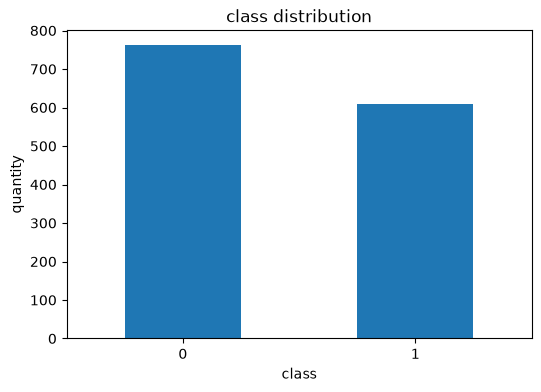

In [15]:
class_counts = df["class"].value_counts().sort_index()
print(class_counts)

class_counts.plot(kind="bar", figsize=(6, 4))
plt.title("class distribution")
plt.xlabel("class")
plt.ylabel("quantity")
plt.xticks(rotation=0)
plt.show()

в датасете:
- 1372 объекта
- 4 числовых признака
- 1 бинарный target

пропусков нет, классы *немного* несбалансированы: 762 объекта класса 0 и 610 класса 1

**есть 24 полных дубля** - удалю их из dataframe, чтобы одинаковые объекты не попали в разные выборки

In [16]:
df = df.drop_duplicates().reset_index(drop=True)
print("Размер после удаления дублей:", df.shape)

Размер после удаления дублей: (1348, 5)


## X и y

для SVM заменяем классы 0 и 1 на -1 и +1. Тогда $y(w^T x + b)$ сразу показывает, правильно ли объект расположен относительно границы

In [17]:
X = df.drop(columns="class")
y = df["class"].replace({0: -1, 1: 1})

print("X:", X.shape)
print("y:", y.shape)
print(y.value_counts().sort_index())

X: (1348, 4)
y: (1348,)
class
-1    738
 1    610
Name: count, dtype: int64


## stratified train / validation / test split

делим каждый класс отдельно в отношении 60 / 20 / 20, чтобы сохранить баланс классов во всех выборках

In [18]:
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []

for class_value in y.unique():  # каждый класс отдельно

    # перемешиваем индексы текущего класса тут
    class_idx = np.where(y.to_numpy() == class_value)[0]
    rng.shuffle(class_idx)

    # split
    train_end = int(0.6 * len(class_idx))
    val_end = int(0.8 * len(class_idx))

    # обновление общих списков
    train_idx.extend(class_idx[:train_end])
    val_idx.extend(class_idx[train_end:val_end])
    test_idx.extend(class_idx[val_end:])

rng.shuffle(train_idx)
rng.shuffle(val_idx)
rng.shuffle(test_idx)

In [9]:
X_train = X.iloc[train_idx].reset_index(drop=True)
X_val = X.iloc[val_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True)
y_val = y.iloc[val_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (808, 4)
Validation: (270, 4)
Test: (270, 4)


In [10]:
split_balance = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).sort_index()

split_balance.round(3)

,train,validation,test
class,,,
-1,0.547,0.548,0.548
1,0.453,0.452,0.452


доли классов почти одинаковые во всех выборках - stratified split сработал

## Scaling

сохраняем данные без scaling и отдельно стандартизируем их

In [19]:
X_train_unscaled = X_train.copy()
X_val_unscaled = X_val.copy()
X_test_unscaled = X_test.copy()

means = X_train.mean()
stds = X_train.std().replace(0, 1)

X_train_scaled = (X_train - means) / stds
X_val_scaled = (X_val - means) / stds
X_test_scaled = (X_test - means) / stds

In [20]:
pd.DataFrame({
    "train mean": X_train_scaled.mean(),
    "train std": X_train_scaled.std(),
}).round(3)

,train mean,train std
variance,-0.0,1.0
skewness,0.0,1.0
curtosis,-0.0,1.0
entropy,0.0,1.0


после scaling среднее каждого train-признака равно 0, а стандартное отклонение - 1

- два варианта данных для сравнения SVM: без scaling и со scaling

## Linear SVM

модель считает линейный score:

$$s_i = w^T x_i + b$$

если $s_i \ge 0$, предсказываем класс $+1$, иначе $-1$. Граница классов задается уравнением $w^T x + b = 0$

margin объекта:

$$m_i = y_i s_i$$

- $m_i \ge 1$ - объект классифицирован правильно и находится за margin
- $0 < m_i < 1$ - класс правильный, но объект находится внутри margin
- $m_i < 0$ - объект классифицирован неправильно

### Hinge loss и регуляризация

ошибка одного объекта:

$$L_i = \max(0, 1 - y_i s_i)$$

если объект находится за margin, его hinge loss равен 0

ошибку дают только объекты внутри margin и неправильно классифицированные объекты

итоговая функция потерь:

$$J(w, b) = \frac{\lambda}{2} \lVert w \rVert^2 + \frac{1}{n} \sum_{i=1}^{n} \max(0, 1-y_i(w^T x_i+b))$$

первая часть - L2-регуляризация. Она ограничивает веса и помогает сделать margin шире. Вторая часть - средний hinge loss

### Subgradient & weights update

для объектов, у которых $y_i s_i < 1$:

$$\nabla_w J = \lambda w - \frac{1}{|B|} \sum y_i x_i$$

$$\nabla_b J = -\frac{1}{|B|} \sum y_i$$

в суммы входят только объекты, нарушающие margin. Делим на размер всего batch, потому что hinge loss усредняется по всему batch

обновление параметров:

$$w \leftarrow w - \eta \nabla_w J$$

$$b \leftarrow b - \eta \nabla_b J$$

перед каждой эпохой train перемешивается и делится на mini-batches. После эпохи считаем hinge loss и полный loss на всем train и сохраняем их для графика

## Проверка обучения (чтобы понять работает ли)

для начала обучим одну SVM на масштабированных данных с фиксированными параметрами. Подбор $\lambda$ и `batch_size` сделаю позже по validation

In [22]:
from linear_svm import LinearSVM

svm = LinearSVM(
    learning_rate=0.01,
    epochs=500,
    lambda_=0.01,
    batch_size=32,
    seed=SEED,
)

svm.fit(X_train_scaled, y_train)

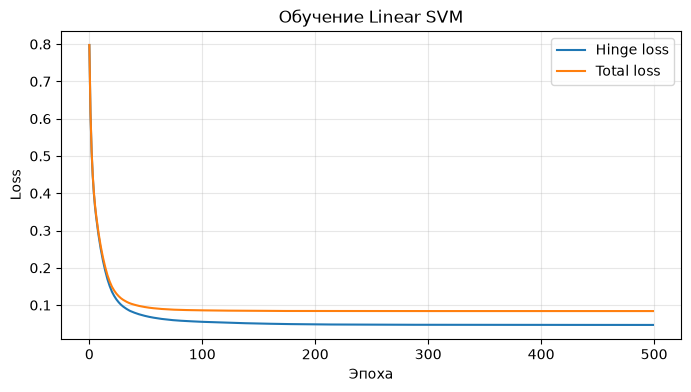

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(svm.hinge_loss_history, label="Hinge loss")
plt.plot(svm.loss_history, label="Total loss")
plt.title("Обучение Linear SVM")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
# примеры предсказаний

check_scores = svm.decision_function(X_val_scaled.iloc[:5])
check_pred = svm.predict(X_val_scaled.iloc[:5])

pd.DataFrame({
    "true": y_val.iloc[:5],
    "score": check_scores.round(3),
    "prediction": check_pred,
})

,true,score,prediction
0,1,1.467,1
1,1,1.720,1
2,1,1.429,1
3,-1,-1.374,-1
4,-1,-2.043,-1


In [26]:
train_pred = svm.predict(X_train_scaled)
val_pred = svm.predict(X_val_scaled)

print("Первый total loss:", round(svm.loss_history[0], 4))
print("Последний total loss:", round(svm.loss_history[-1], 4))
print("Train Accuracy:", round(np.mean(train_pred == y_train), 4))
print("Validation Accuracy:", round(np.mean(val_pred == y_val), 4))

Первый total loss: 0.7978
Последний total loss: 0.0841
Train Accuracy: 0.9876
Validation Accuracy: 0.9778


## Подбор гиперпараметров

подбираем $\lambda$, `batch_size` и scaling по validation (ну как в прошлой лабе). 

Основной метрикой я взял F1, при равном F1 смотрим на ROC-AUC

для поиска используем 300 эпох для всех вариантов

### Метрики

Accuracy показывает общую долю правильных ответов

Precision показывает, какая доля предсказанного класса $+1$ действительно относится к $+1$

Recall показывает, какую долю настоящего класса $+1$ нашла модель

F1 объединяет Precision и Recall

ROC-AUC оценивает качество ранжирования по непрерывному score

In [ ]:
def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == -1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == -1))

    accuracy = np.mean(y_true == y_pred)
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

    return accuracy, precision, recall, f1


def roc_auc(y_true, scores):
    """Площадь под ROC-кривой"""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    order = np.argsort(scores)[::-1]
    sorted_y = y_true[order]

    # [a, b, c] [a, a+b, a+b+c]

    tp = np.cumsum(sorted_y == 1)
    fp = np.cumsum(sorted_y == -1)

    tpr = np.r_[0, tp / tp[-1]] # получаем кривую добавив точку (0,0)
    fpr = np.r_[0, fp / fp[-1]]

    return np.trapezoid(tpr, fpr) # площадь методом трапеций (интеграл)

In [ ]:
lambda_values = [0.0001, 0.001, 0.01, 0.1]
batch_sizes = [1, 16, 32, 64, 128, None]

variants = [
    ("без scaling", X_train_unscaled, X_val_unscaled),
    ("со scaling", X_train_scaled, X_val_scaled),
]

results = []

for scaling, X_train_part, X_val_part in variants:
    for lambda_ in lambda_values:
        for batch_size in batch_sizes:
            model = LinearSVM(
                learning_rate=0.01,
                epochs=300,
                lambda_=lambda_,
                batch_size=batch_size,
                seed=SEED,
            )
            
            model.fit(X_train_part, y_train)

            y_pred = model.predict(X_val_part)
            scores = model.decision_function(X_val_part)
            accuracy, precision, recall, f1 = classification_metrics(y_val, y_pred)

            results.append([
                scaling,
                lambda_,
                "full" if batch_size is None else str(batch_size),
                accuracy,
                precision,
                recall,
                f1,
                roc_auc(y_val, scores),
            ])

validation_results = pd.DataFrame(
    results,
    columns=[
        "scaling", "lambda", "batch_size", "Accuracy",
        "Precision", "Recall", "F1", "ROC-AUC",
    ],
)

validation_results.sort_values(
    ["F1", "ROC-AUC"], ascending=False
).head(10).round(4)

,scaling,lambda,batch_size,Accuracy,Precision,Recall,F1,ROC-AUC
1,без scaling,0.0001,16,0.9926,0.9839,1.0,0.9919,0.9999
0,без scaling,0.0001,1,0.9926,0.9839,1.0,0.9919,0.9998
7,без scaling,0.0010,16,0.9889,0.9760,1.0,0.9879,1.0000
2,без scaling,0.0001,32,0.9889,0.9760,1.0,0.9879,0.9999
3,без scaling,0.0001,64,0.9889,0.9760,1.0,0.9879,0.9999
4,без scaling,0.0001,128,0.9889,0.9760,1.0,0.9879,0.9999
8,без scaling,0.0010,32,0.9889,0.9760,1.0,0.9879,0.9999
9,без scaling,0.0010,64,0.9889,0.9760,1.0,0.9879,0.9999
10,без scaling,0.0010,128,0.9889,0.9760,1.0,0.9879,0.9999
13,без scaling,0.0100,16,0.9889,0.9760,1.0,0.9879,0.9999


In [29]:
best_result = validation_results.sort_values(
    ["F1", "ROC-AUC"], ascending=False
).iloc[0]

best_result

scaling       без scaling
lambda             0.0001
batch_size             16
Accuracy         0.992593
Precision        0.983871
Recall                1.0
F1                0.99187
ROC-AUC          0.999889
Name: 1, dtype: object

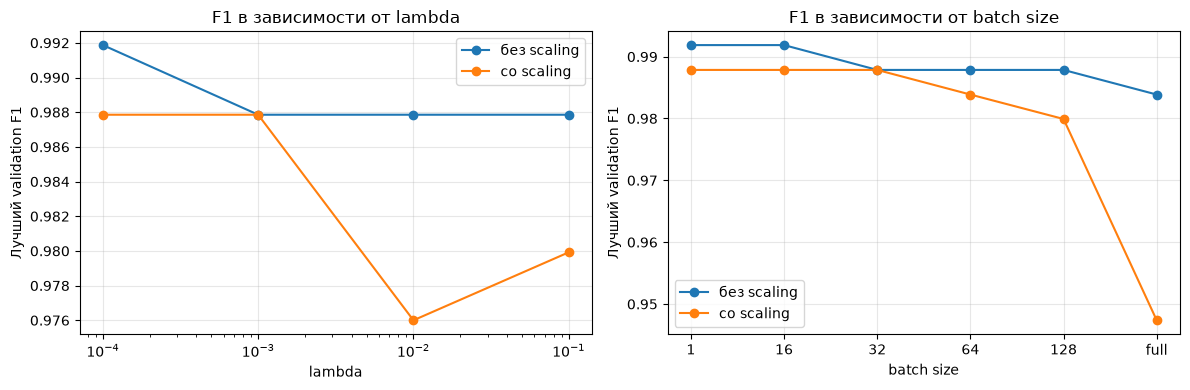

In [31]:
# завайбкоженные графики зависимости F1(lambda) and F1(batch_size)

lambda_summary = validation_results.groupby(
    ["scaling", "lambda"], as_index=False
)["F1"].max()

batch_summary = validation_results.groupby(
    ["scaling", "batch_size"], sort=False, as_index=False
)["F1"].max()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for scaling in validation_results["scaling"].unique():
    part = lambda_summary[lambda_summary["scaling"] == scaling]
    axes[0].plot(part["lambda"], part["F1"], marker="o", label=scaling)

    part = batch_summary[batch_summary["scaling"] == scaling]
    axes[1].plot(part["batch_size"], part["F1"], marker="o", label=scaling)

axes[0].set_xscale("log")
axes[0].set_title("F1 в зависимости от lambda")
axes[0].set_xlabel("lambda")
axes[0].set_ylabel("Лучший validation F1")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("F1 в зависимости от batch size")
axes[1].set_xlabel("batch size")
axes[1].set_ylabel("Лучший validation F1")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

лучший validation-вариант:

- без scaling
- $\lambda = 0.0001$
- `batch_size = 16`
- Accuracy = 0.9926
- F1 = 0.9919
- ROC-AUC = 0.9999

вариант со scaling тоже показал высокое качество, но немного уступил. Полный batch оказался хуже mini-batch, особенно на масштабированных данных

## Итоговая оценка SVM

обучаем модель с лучшими validation-параметрами и только теперь проверяем ее на test

In [32]:
final_svm = LinearSVM(
    learning_rate=0.01,
    epochs=300,
    lambda_=0.0001,
    batch_size=16,
    seed=SEED,
)

final_svm.fit(X_train_unscaled, y_train)
test_pred = final_svm.predict(X_test_unscaled)
test_scores = final_svm.decision_function(X_test_unscaled)

In [33]:
def roc_curve_points(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    order = np.argsort(scores)[::-1]
    sorted_y = y_true[order]

    tp = np.cumsum(sorted_y == 1)
    fp = np.cumsum(sorted_y == -1)

    tpr = np.r_[0, tp / tp[-1]]
    fpr = np.r_[0, fp / fp[-1]]
    return fpr, tpr


def precision_recall_curve_points(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    order = np.argsort(scores)[::-1]
    sorted_y = y_true[order]

    tp = np.cumsum(sorted_y == 1)
    fp = np.cumsum(sorted_y == -1)

    precision = np.r_[1, tp / (tp + fp)]
    recall = np.r_[0, tp / tp[-1]]
    return recall, precision

In [34]:
accuracy, precision, recall, f1 = classification_metrics(y_test, test_pred)

fpr, tpr = roc_curve_points(y_test, test_scores)
pr_recall, pr_precision = precision_recall_curve_points(y_test, test_scores)

roc_auc_value = np.trapezoid(tpr, fpr)
pr_auc_value = np.trapezoid(pr_precision, pr_recall)

test_metrics = pd.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1": [f1],
    "ROC-AUC": [roc_auc_value],
    "PR-AUC": [pr_auc_value],
})

test_metrics.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1.0,1.0,1.0,1.0,1.0,1.0


вот это да! похоже, данные идеально линейно разделимы!!

In [35]:
tn = np.sum((y_test == -1) & (test_pred == -1))
fp = np.sum((y_test == -1) & (test_pred == 1))
fn = np.sum((y_test == 1) & (test_pred == -1))
tp = np.sum((y_test == 1) & (test_pred == 1))

confusion = np.array([
    [tn, fp],
    [fn, tp],
])

pd.DataFrame(
    confusion,
    index=["true -1", "true +1"],
    columns=["pred -1", "pred +1"],
)

,pred -1,pred +1
true -1,148,0
true +1,0,122


крутяк)

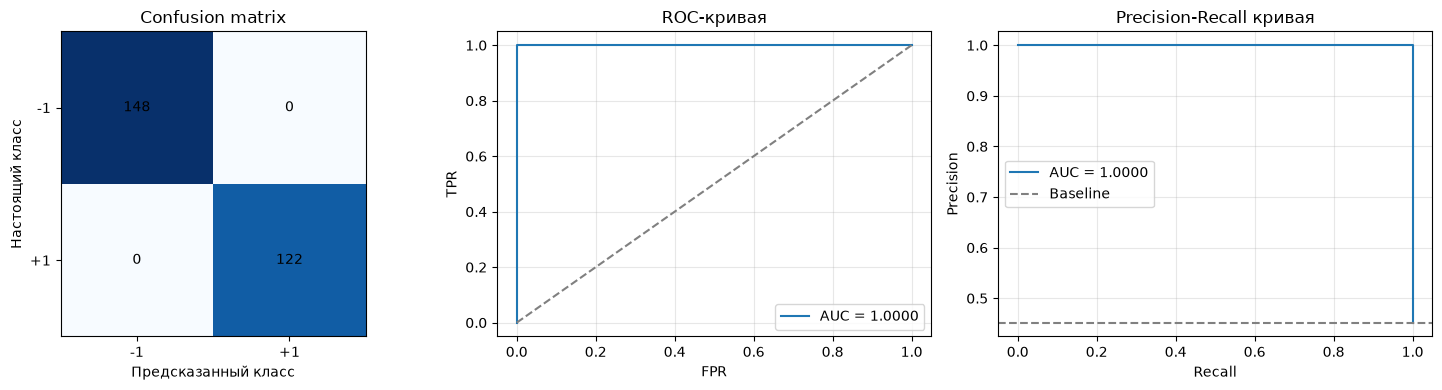

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(confusion, cmap="Blues")
axes[0].set_title("Confusion matrix")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["-1", "+1"])
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["-1", "+1"])
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Настоящий класс")

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, confusion[i, j], ha="center", va="center")

axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_value:.4f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC-кривая")
axes[1].set_xlabel("FPR")
axes[1].set_ylabel("TPR")
axes[1].legend()
axes[1].grid(alpha=0.3)

positive_rate = np.mean(y_test == 1)
axes[2].plot(pr_recall, pr_precision, label=f"AUC = {pr_auc_value:.4f}")
axes[2].axhline(positive_rate, linestyle="--", color="gray", label="Baseline")
axes[2].set_title("Precision-Recall кривая")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

итак, что мы имеем:

- на test модель не допустила ошибок: 
    - правильно определены 148 объектов класса -1 и 122 объекта класса +1

**все итоговые метрики равны 1** ROC-AUC и PR-AUC показывают, что положительные и отрицательные объекты полностью разделяются по score

(это результат на конкретном split)

## Сравнение с Logistic Regression

используем свою логрег модель из первой лабы. Обе модели обучаются на одном split и одинаковых признаках без scaling

для LogReg возвращаем target к формату 0 и 1. ROC-AUC и PR-AUC считаем по вероятностям из `predict_proba()`

In [42]:
from log_reg import LogisticRegression

y_train_log = (y_train == 1).astype(int)

log_reg = LogisticRegression(
    learning_rate=0.1,
    epochs=1000,
    threshold=0.5,
)

log_reg.fit(X_train_unscaled, y_train_log)

log_probabilities = log_reg.predict_proba(X_test_unscaled)
log_pred = np.where(log_reg.predict(X_test_unscaled) == 1, 1, -1)

In [43]:
log_accuracy, log_precision, log_recall, log_f1 = classification_metrics(
    y_test, log_pred
)

log_fpr, log_tpr = roc_curve_points(y_test, log_probabilities)
log_pr_recall, log_pr_precision = precision_recall_curve_points(
    y_test, log_probabilities
)

log_roc_auc = np.trapezoid(log_tpr, log_fpr)
log_pr_auc = np.trapezoid(log_pr_precision, log_pr_recall)

comparison = pd.DataFrame([
    ["Linear SVM", accuracy, precision, recall, f1, roc_auc_value, pr_auc_value],
    ["Logistic Regression", log_accuracy, log_precision, log_recall, log_f1, log_roc_auc, log_pr_auc],
], columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC",
])

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Linear SVM,1.0,1.0,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0,1.0,1.0


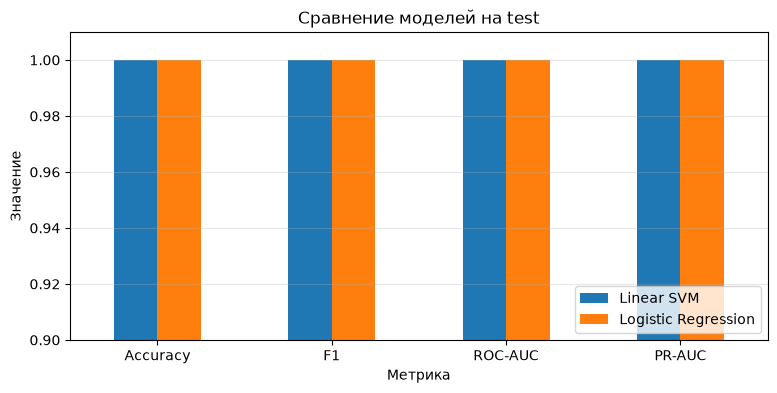

In [44]:
comparison.set_index("Model")[[
    "Accuracy", "F1", "ROC-AUC", "PR-AUC"
]].T.plot(kind="bar", figsize=(9, 4), ylim=(0.9, 1.01))

plt.title("Сравнение моделей на test")
plt.xlabel("Метрика")
plt.ylabel("Значение")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.show()

обе линейные модели получили идеальные test-метрики. На этом датасете классы хорошо разделяются линейной границей, поэтому разницы в итоговом качестве нет

напомню себе, что при этом SVM возвращает score и максимизирует margin, а Logistic Regression возвращает вероятность и минимизирует BCE

## 2D-визуализация SVM

основная модель использует все 4 признака, поэтому ее границу нельзя напрямую нарисовать на плоскости

для визуализации обучаем отдельную SVM только на `variance` и `skewness`.

(warning) ее метрики не считаются итоговыми

In [45]:
features_2d = ["variance", "skewness"]

X_train_2d = X_train_unscaled[features_2d]
X_val_2d = X_val_unscaled[features_2d]

svm_2d = LinearSVM(
    learning_rate=0.01,
    epochs=300,
    lambda_=0.0001,
    batch_size=16,
    seed=SEED,
)

svm_2d.fit(X_train_2d, y_train)

train_2d_pred = svm_2d.predict(X_train_2d)
val_2d_pred = svm_2d.predict(X_val_2d)

print("2D Train Accuracy:", round(np.mean(train_2d_pred == y_train), 4))
print("2D Validation Accuracy:", round(np.mean(val_2d_pred == y_val), 4))

2D Train Accuracy: 0.8899
2D Validation Accuracy: 0.9


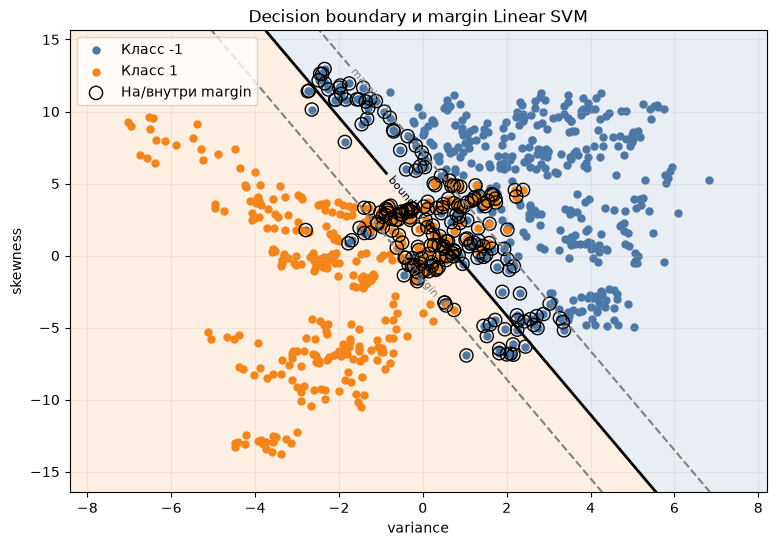

In [46]:
x_min, x_max = X_train_2d["variance"].min(), X_train_2d["variance"].max()
y_min, y_max = X_train_2d["skewness"].min(), X_train_2d["skewness"].max()

x_padding = 0.1 * (x_max - x_min)
y_padding = 0.1 * (y_max - y_min)

xx, yy = np.meshgrid(
    np.linspace(x_min - x_padding, x_max + x_padding, 300),
    np.linspace(y_min - y_padding, y_max + y_padding, 300),
)

grid = np.column_stack([xx.ravel(), yy.ravel()])
grid_scores = svm_2d.decision_function(grid).reshape(xx.shape)

train_scores = svm_2d.decision_function(X_train_2d)
train_margins = y_train.to_numpy() * train_scores
margin_mask = train_margins <= 1

# вайбкод графики

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, grid_scores,
    levels=[grid_scores.min(), 0, grid_scores.max()],
    colors=["#4C78A8", "#F58518"],
    alpha=0.12,
)

for class_value, color in [(-1, "#4C78A8"), (1, "#F58518")]:
    mask = y_train == class_value
    plt.scatter(
        X_train_2d.loc[mask, "variance"],
        X_train_2d.loc[mask, "skewness"],
        color=color,
        s=25,
        label=f"Класс {class_value}",
    )

lines = plt.contour(
    xx, yy, grid_scores,
    levels=[-1, 0, 1],
    colors=["gray", "black", "gray"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2, 1.5],
)

plt.clabel(
    lines,
    fmt={-1: "margin -1", 0: "boundary", 1: "margin +1"},
    fontsize=8,
)

plt.scatter(
    X_train_2d.loc[margin_mask, "variance"],
    X_train_2d.loc[margin_mask, "skewness"],
    facecolors="none",
    edgecolors="black",
    s=90,
    linewidths=1,
    label="На/внутри margin",
)

plt.title("Decision boundary и margin Linear SVM")
plt.xlabel("variance")
plt.ylabel("skewness")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

сплошная черная линия - decision boundary $w^T x + b = 0$

пунктирные линии - границы margin $w^T x + b = -1$ и $w^T x + b = 1$

объекты в черных окружностях находятся на margin или внутри него и сильнее всего влияют на hinge loss

Accuracy 2D-модели на validation получилась около 0.90. Она ниже основной модели

## ВЫВОД

лучший результат на validation показала SVM без scaling с $\lambda = 0.0001$ и `batch_size = 16`. На test модель получила Accuracy, F1, ROC-AUC и PR-AUC равные 1.0 и не допустила ошибок

Scaling в этом эксперименте немного ухудшил результат. Большого разрыва между train и validation нет, поэтому явных признаков overfit или underfit у основной модели не наблюдается

SVM и Logistic Regression показали одинаковое итоговое качество, но обучаются по-разному: SVM максимизирует margin через hinge loss, а Logistic Regression минимизирует BCE и возвращает вероятности

отдельная 2D-модель показала более низкую точность, потому что использовала только два признака. Она нужна только для визуализации decision boundary, margin и объектов, которые сильнее всего влияют на обучение